# Dual FEG: terminal residual and Lyapunov discovery
Let $A$ be a monotone, $L$-Lipschitz operator on a finite-dimensional real Euclidean space, with $L>0$, $A(x_\star)=0$, $\|x_0-x_\star\|^2\le R^2$, $R\ge0$, and $z_0=0$. For an integer horizon $N\ge1$ and $\alpha=1/L$:
$$y_k=x_k-\alpha z_k-\alpha A(x_k),$$
$$x_{k+1}=y_k-\frac{N-k-1}{N-k}\alpha(A(y_k)-A(x_k)),$$
$$z_{k+1}=\frac{N-k-1}{N-k}z_k-\frac{A(y_k)}{N-k},\qquad 0\le k<N.$$
The selected performance metric is $\|A(x_N)\|^2$. We investigate the conjectured upper bound $4L^2R^2/N^2$.

## Proof Statement

### Theorem
For every integer $N\ge1$, $L>0$, and $R\ge0$, let $A$ be monotone and $L$-Lipschitz on a real finite-dimensional Euclidean space. Assume $A(x_{\star})=0$, $\|x_{0}-x_{\star}\|^{2}\le R^{2}$, and $z_{0}=0$. The supplied dual FEG iteration with $\alpha=1/L$ satisfies
$$\boxed{\|A(x_{N})\|^{2}\le\frac{4L^{2}R^{2}}{N^{2}}.}$$
Set $X=x_{N}$, $G=A(X)$ and $t=N-k$. A nonincreasing certificate is $V_{0}=0$, and, for $1\le k<N$,
$$V_{k}=-4\langle G,z_{k}\rangle-2\|z_{k}\|^{2}+\frac{4L}{N-k}\langle G+z_{k},x_{k}-X\rangle+\frac{4L}{N}\langle G,X-x_{0}\rangle.$$
The terminal value is
$$V_{N}=2\|G\|^{2}+\frac{4L}{N}\langle G,X-x_{0}\rangle.$$
The same interior expression evaluated at $k=0$, $z_{0}=0$ equals zero; its denominator is never used at $k=N$.

### Proof outline
Write $X=x_{N}$, $G=A(X)$ and
$$\Phi(t,x,z)=-4\langle G,z\rangle-2\|z\|^{2}+\frac{4L}{t}\langle G+z,x-X\rangle+\frac{4L}{N}\langle G,X-x_{0}\rangle.$$
Thus $V_{k}=\Phi(N-k,x_{k},z_{k})$ for $k<N$, $V_{0}=0$, and $V_{N}=2\|G\|^{2}+(4L/N)\langle G,X-x_{0}\rangle$.
Define the nonpositive residuals
$$\operatorname{Lip}(u,v)=\|A(u)-A(v)\|^{2}-L^{2}\|u-v\|^{2},\qquad
\operatorname{Mon}(u,v)=-\langle A(u)-A(v),u-v\rangle.$$
Substituting the iteration gives, for $0\le k\le N-2$ and $t=N-k\ge2$,
$$V_{k+1}-V_{k}=\frac{2}{t^{2}}\operatorname{Lip}(x_{k},y_{k})+\frac{4L}{t(t-1)}\operatorname{Mon}(X,y_{k})\le0.$$
All coefficients are positive. At the last step, $X=y_{N-1}=x_{N-1}-(z_{N-1}+A(x_{N-1}))/L$, and
$$V_{N}-V_{N-1}=2\operatorname{Lip}(x_{N-1},X)\le0.$$
For $N=1$, the separate direct identity is $V_{1}=2\operatorname{Lip}(x_{0},x_{1})\le0$, so every horizon has $V_{N}\le V_{0}=0$.
Finally, with $d=x_{0}-x_{\star}$,
$$\|G\|^{2}-\frac{4L^{2}R^{2}}{N^{2}}
=V_{N}+\frac{4L}{N}\operatorname{Mon}(X,x_{\star})
-\left\|\frac{2L}{N}d-G\right\|^{2}
+\frac{4L^{2}}{N^{2}}(\|d\|^{2}-R^{2})\le0.$$
The last inequality uses monotonicity, nonnegativity of a squared norm, and the initial radius bound. This proves the theorem, including $R=0$, without dividing by $R$.

In [1]:
import sys
from pathlib import Path
notebook_dir = Path.cwd().resolve()
repo_root = notebook_dir / "supplementary" / "approved"
sys.path[:0] = [str(repo_root), str(notebook_dir / "supplementary" / "helpers")]


In [2]:
import runtime
import json
import matplotlib.pyplot as plt
import pepflow as pf
import sympy as sp
assert runtime.NOTEBOOK_DIR == notebook_dir
assert Path(pf.__file__).resolve().is_relative_to(repo_root)


In [3]:
L = pf.Parameter("L")
R = pf.Parameter("R")
A = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A"], L=L)

In [4]:
def make_ctx_dual_feg(ctx_name: str, N, **kwargs):
    ctx = pf.PEPContext(ctx_name).set_as_current()
    x = pf.Vector(is_basis=True, tags=["x_0"])
    A.set_zero_point("x_star")
    z = pf.Vector.zero().add_tag("z_0")
    for k in range(int(N)):
        t = sp.Integer(N - k)
        g = A(x).add_tag(f"g_{k}")
        y = (x - z / L - g / L).add_tag(f"y_{k}")
        h = A(y).add_tag(f"h_{k}")
        x = (y - ((t - 1) / t) * (h - g) / L).add_tag(f"x_{k+1}")
        z = (((t - 1) / t) * z - h / t).add_tag(f"z_{k+1}")
    A(x).add_tag(f"g_{N}")
    return ctx


def get_pep_setup(N, params):
    ctx = make_ctx_dual_feg(f"ctx_{N}", N)
    pb = pf.PEPBuilder(ctx)
    pb.add_initial_constraint(((ctx["x_0"] - ctx["x_star"]) ** 2).le(R**2, name="initial_condition"))
    pb.set_performance_metric(A(ctx[f"x_{N}"]) ** 2)
    return ctx, pb, A


## Numerical evidence
A single CLARABEL-default sweep was performed for $N=1,\ldots,7$. The $N=1$ status was `optimal_inaccurate`; all remaining statuses were `optimal`. The conjecture is an upper bound and is not tight at $N=1$.

N=1: 1.9999999321; optimal_inaccurate; N^2 value=1.9999999321
N=2: 0.9999999977; optimal; N^2 value=3.9999999907
N=3: 0.4444444512; optimal; N^2 value=4.0000000606
N=4: 0.2500000015; optimal; N^2 value=4.0000000243
N=5: 0.1600000034; optimal; N^2 value=4.0000000852
N=6: 0.1111111136; optimal; N^2 value=4.0000000905
N=7: 0.0816326559; optimal; N^2 value=4.0000001388


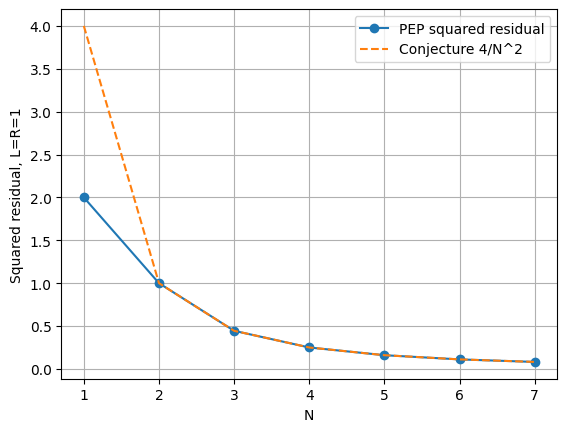

Setup reconstruction available: 7 basis vectors


In [5]:
evidence = json.loads((notebook_dir / "state/dual_feg_b1.json").read_text())
rows = evidence["sweep_results"]
for row in rows:
    print(f'N={row["N"]}: {row["opt_value"]:.10f}; {row["status"]}; N^2 value={row["N"]**2*row["opt_value"]:.10f}')
ns = [row["N"] for row in rows]
plt.plot(ns, [row["opt_value"] for row in rows], "o-", label="PEP squared residual")
plt.plot(ns, [4/n**2 for n in ns], "--", label="Conjecture 4/N^2")
plt.xlabel("N")
plt.ylabel("Squared residual, L=R=1")
plt.legend()
plt.grid(True)
plt.show()
ctx, pb, obj = get_pep_setup(2, {"L": 1, "R": 1})
print("Setup reconstruction available:", len(ctx.basis_vectors()), "basis vectors")

## Dense and relaxed proof solves
The dense $N=6$ solve was followed by a threshold relaxation dropping multipliers below $10^{-6}$. A second structural relaxation keeps terminal monotonicity to the zero and $y_0,\ldots,y_{N-2}$, plus step Lipschitz inequalities. The last step uses $(x_{N-1},x_N)$ because $x_N=y_{N-1}$; the unused duplicate evaluation is omitted. All selected components are from one fresh CLARABEL solve. Saved certificate values are revalidated below without solving again.

In [6]:
import hashlib
import numpy as np
from fractions import Fraction
b2 = json.loads((notebook_dir / "state/dual_feg_b2.json").read_text())
dense = json.loads((notebook_dir / "state/dual_feg_dense.json").read_text())
threshold = json.loads((notebook_dir / "supplementary/b2-threshold-certificate.json").read_text())
print("Dense objective:", dense["opt_value"], "basis:", dense["basis_vectors"])
for group in dense["lambda_groups"]:
    active = [(name, value) for name, value in dense["named_dual_values"].items() if dense["constraint_metadata"][name]["group"] == group and value is not None and value > 1e-6]
    print(group, "active count:", len(active))
    print(active)
print("Dense S eigenvalues:", np.linalg.eigvalsh(np.array(dense["S_matrix"])))
print("Threshold attempt gap:", threshold["sparsity_selection"]["dense_gap"])
print("Selected structural relaxation:", b2["sparsity_selection"])
print("Dropped constraints:", len(b2["relaxed_constraints"]))
for name, value in b2["named_dual_values"].items():
    if value is not None:
        print(name, value, "near", Fraction(value).limit_denominator(1000))


Dense objective: 0.11111111362413659 basis: ['x_0', 'x_star', 'g_0', 'h_0', 'g_1', 'h_1', 'g_2', 'h_2', 'g_3', 'h_3', 'g_4', 'h_4', 'g_5', 'h_5', 'g_6']
Monotone Operator Inequality active count: 13
[('A monotone:x_6,x_star', 0.6666277784084684), ('A monotone:x_6,y_0', 0.13332569958931756), ('A monotone:x_6,y_1', 0.19998701512125716), ('A monotone:x_6,y_2', 0.3333098711409026), ('A monotone:x_6,y_3', 0.6666366868202113), ('A monotone:x_6,y_4', 1.9999350220695538), ('A monotone:x_6,y_5', 0.22599304360369404), ('A monotone:x_star,y_5', 3.898518484268299e-05), ('A monotone:y_0,y_5', 7.659908858993752e-06), ('A monotone:y_1,y_5', 1.3018407055245164e-05), ('A monotone:y_2,y_5', 2.350932120072067e-05), ('A monotone:y_3,y_5', 3.0070853273386462e-05), ('A monotone:y_4,y_5', 6.524296972965166e-05)]
Lipschitz Continuous Inequality active count: 8
[('A Lipschitz:x_0,y_0', 0.055555568994121986), ('A Lipschitz:x_1,y_1', 0.08000001871723995), ('A Lipschitz:x_2,y_2', 0.12500002369537433), ('A Lipschi

## Lambda and S verification
The numerical certificate uses residuals $r\le0$ and the identity
$$\|A(x_N)\|^2-\tau-\sum_i\lambda_i r_i+S=0.$$
Every active multiplier and all numerical LDL factors are retained. The initial residual is $\|x_0-x_\star\|^2-R^2$.

At $L=R=1$, inspection suggests terminal monotonicity weights $4/N$ to the zero and $4/[t(t-1)]$ to $y_k$, $t=N-k\ge2$; Lipschitz weights are $2/t^2$. The remainder candidate is
$$S_{\rm guess}=\left\|\frac{2}{N}(x_0-x_\star)-A(x_N)\right\|^2.$$
These are candidates supported at the selected horizon, not an arbitrary-horizon proof. No pre-existing mathematical sources were authorized. Numerical reverse LDL is kept as the exact decomposition of the selected numerical matrix.

In [7]:
selected = json.loads((notebook_dir / 'state/dual_feg_relaxed.json').read_text())
b1 = json.loads((notebook_dir / 'state/dual_feg_b1.json').read_text())
dense = json.loads((notebook_dir / 'state/dual_feg_dense.json').read_text())
N = selected['N']
params: dict[str, pf.NUMERICAL_TYPE] = {'L': sp.Integer(1), 'R': sp.Integer(1)}
ctx, pb, obj = get_pep_setup(N, params)
ctx.set_as_current()
pm = pf.ExpressionManager(ctx, resolve_parameters=params)
assert selected['basis_vectors'] == [str(v) for v in ctx.basis_vectors()]
assert selected['basis_scalars'] == [str(v) for v in ctx.basis_scalars()]
entries = list(pb.init_conditions) + obj.get_interpolation_constraints(ctx)
assert {c.name for c in entries} == set(selected['named_dual_values'])
for relative, expected in selected['certificate_provenance']['source_hashes'].items():
    assert hashlib.sha256((notebook_dir / relative).read_bytes()).hexdigest() == expected
weighted = pf.Scalar.zero()
values = []
for constraint in entries:
    value = selected['named_dual_values'][constraint.name]
    metadata = selected['constraint_metadata'][constraint.name]
    assert metadata['comparator'] == constraint.cmp.value
    if metadata['relaxed']:
        assert value is None
        continue
    assert value is not None
    residual = constraint.lhs - constraint.rhs
    if constraint.cmp in (pf.Comparator.GE, pf.Comparator.SEQ):
        residual = -residual
    weighted += float(value) * residual
    if constraint.cmp != pf.Comparator.EQ:
        values.append(float(value))
S_array = np.array(selected['S_matrix'], dtype=float)
D = np.array(selected['numerical_decomposition']['D'], dtype=float)
E = np.array(selected['numerical_decomposition']['ell_coords'], dtype=float)
basis = ctx.basis_vectors()
ell = [sum((float(a) * v for a, v in zip(row, basis)), pf.Vector.zero()) for row in E]
S_numeric = sum((float(D[i,j]) * ell[i] * ell[j] for i,j in np.ndindex(D.shape)), pf.Scalar.zero())
assert pb.performance_metric is not None
identity = pb.performance_metric - selected['opt_value'] - weighted + S_numeric
checked = pm.eval_scalar(identity)
def max_abs(values):
    return float(np.max(np.abs(np.asarray(values, dtype=float)), initial=0.0))
residuals = dict(identity_gram_max_abs=max_abs(checked.inner_prod_coords), identity_func_max_abs=max_abs(checked.func_coords),
    identity_offset_abs=max_abs(checked.offset), S_reconstruction_max_abs=max_abs(E.T @ D @ E-S_array),
    dense_relaxed_gap=abs(dense['opt_value']-selected['opt_value']),
    minimum_scalar_inequality_dual=min(values), minimum_S_eigenvalue=float(np.linalg.eigvalsh(S_array).min()),
    minimum_matrix_inequality_eigenvalue=0.0)
tolerances = dict(identity_atol=1e-5, identity_rtol=0.0, reconstruction_atol=1e-4, reconstruction_rtol=1e-5, dual_tol=1e-6, psd_tol=1e-6, dense_opt_atol=1e-5)
assert selected['certificate_provenance']['solver_status'] == 'optimal'
assert np.isfinite(S_array).all() and np.allclose(S_array,S_array.T,atol=1e-6,rtol=0)
assert max(residuals[k] for k in ['identity_gram_max_abs','identity_func_max_abs','identity_offset_abs']) <= 1e-5
assert np.allclose(E.T @ D @ E,S_array,atol=1e-4,rtol=1e-5)
assert residuals['dense_relaxed_gap'] < 1e-5
assert min(values) >= -1e-6 and residuals['minimum_S_eigenvalue'] >= -1e-6
assert abs(selected['opt_value']-4/N**2) < 1e-5
print('Complete numerical certificate:', residuals)
pf.pprint_labeled_matrix(np.asarray(checked.inner_prod_coords, dtype=float), row_labels=selected['basis_vectors'], precision=8)
print('Function and offset residuals:', checked.func_coords, checked.offset)

# Candidate lambda formulas at L=1; zeros correspond exactly to the selected sparse pattern.
def lambda_candidate(name, N):
    if name == 'initial_condition':
        return sp.Rational(4,N**2)
    if name == f'A monotone:x_{N},x_star':
        return sp.Rational(4,N)
    for k in range(N-1):
        t=N-k
        if name == f'A monotone:x_{N},y_{k}':
            return sp.Rational(4,t*(t-1))
        if name == f'A Lipschitz:x_{k},y_{k}':
            return sp.Rational(2,t**2)
    if name == f'A Lipschitz:x_{N-1},x_{N}':
        return sp.Integer(2)
    return sp.Integer(0)
lambda_error = max(abs(float(lambda_candidate(name,N))-float(value)) for name,value in selected['named_dual_values'].items() if value is not None)
assert lambda_error <= 1e-4
S_guess = (sp.Rational(2,N) * (ctx['x_0']-ctx['x_star']) - ctx[f'g_{N}'])**2
S_guess_eval = pm.eval_scalar(S_guess)
S_guess_error = max_abs(np.asarray(S_guess_eval.inner_prod_coords,dtype=float)-S_array)
assert S_guess_error <= 1e-4
assert max_abs(S_guess_eval.func_coords) == 0 and max_abs(S_guess_eval.offset) == 0
candidate_weighted = pf.Scalar.zero()
for constraint in entries:
    residual=constraint.lhs-constraint.rhs
    if constraint.cmp in (pf.Comparator.GE,pf.Comparator.SEQ):
        residual=-residual
    candidate_weighted += lambda_candidate(constraint.name,N)*residual
candidate_identity = pm.eval_scalar(pb.performance_metric-sp.Rational(4,N**2)-candidate_weighted+S_guess)
candidate_residual=max(max_abs(candidate_identity.inner_prod_coords),max_abs(candidate_identity.func_coords),max_abs(candidate_identity.offset))
assert candidate_residual < 1e-12
print('Lambda candidate error:',lambda_error,'S candidate error:',S_guess_error,'fixed-N candidate identity:',candidate_residual)
pf.pprint_labeled_matrix(np.asarray(S_guess_eval.inner_prod_coords,dtype=float),row_labels=selected['basis_vectors'])
print('Numerical reverse-LDL diagonal (all entries retained):',np.diag(D))
print('Analytic full-PEP proof: unresolved for arbitrary N; candidate identities above are fixed-N checks.')

Complete numerical certificate: {'identity_gram_max_abs': 1.866268550956371e-09, 'identity_func_max_abs': 0.0, 'identity_offset_abs': 6.914619710141068e-10, 'S_reconstruction_max_abs': 2.7755575615628914e-17, 'dense_relaxed_gap': 3.0603526796069147e-09, 'minimum_scalar_inequality_dual': 0.05555500006895933, 'minimum_S_eigenvalue': 1.1837591864454828e-10, 'minimum_matrix_inequality_eigenvalue': 0.0}


<IPython.core.display.Math object>

Function and offset residuals: [] 6.91461971014107e-10


Lambda candidate error: 2.0027061521155076e-05 S candidate error: 2.002695544300881e-05 fixed-N candidate identity: 8.326672684688674e-17


<IPython.core.display.Math object>

Numerical reverse-LDL diagonal (all entries retained): [9.99979973e-01 5.66428127e-10 4.80638875e-10 4.90625555e-10
 5.39407243e-10 7.43139197e-10 5.04717637e-10 7.14136984e-10
 4.95109854e-10 7.70385297e-10 4.76556282e-10 7.14925983e-10
 4.66926385e-10 6.33269125e-10 6.26214116e-10]
Analytic full-PEP proof: unresolved for arbitrary N; candidate identities above are fixed-N checks.


In [8]:
pf.pprint_labeled_matrix(E, row_labels=[f"ell_{i}" for i in range(len(E))], column_labels=selected["basis_vectors"])
for group, display in selected["lambda_groups"].items():
    row_names, col_names = display["row_names"], display["col_names"]
    candidate = np.zeros((len(row_names), len(col_names)))
    for i, ri in enumerate(row_names):
        for j, cj in enumerate(col_names):
            prefix = "A monotone" if "Monotone" in group else "A Lipschitz"
            name = f"{prefix}:{ri},{cj}"
            candidate[i,j] = float(lambda_candidate(name,N))
    print("Candidate group:", group)
    pf.pprint_labeled_matrix(candidate, row_labels=row_names, column_labels=col_names)
print("Initial closed-form search:", b2["closed_form_search"])

print("Selected numerical S:")
pf.pprint_labeled_matrix(S_array, row_labels=selected["basis_vectors"])


<IPython.core.display.Math object>

Candidate group: Monotone Operator Inequality


<IPython.core.display.Math object>

Candidate group: Lipschitz Continuous Inequality


<IPython.core.display.Math object>

Initial closed-form search: {'completed': True, 'references_reviewed': ['Own dense and sparse certificates; no pre-existing mathematical references authorized'], 'attempts': [{'method': 'Inspect rational fractions of terminal monotonicity and per-step Lipschitz multipliers', 'candidate': '4/[t(t-1)], 4/N, 2/t^2 at L=1', 'max_abs_error': 2.0027061521155076e-05}, {'method': 'Inspect rank-one S and coordinates', 'candidate': '||(2/N)(x0-xstar)-gN||^2 at L=1', 'max_abs_error': 2.002695544300881e-05, 'fixed_N_identity_residual': 8.326672684688674e-17}], 'unresolved_components': ['arbitrary-horizon and parameter-domain proof of candidate lambda/S']}
Selected numerical S:


<IPython.core.display.Math object>

## Partial-sum Lyapunov construction and rank profile
Use the selected coherent $N=6$ certificate, and define $V_0=0$. With $r_{\rm Lip}(u,v)=\|A(u)-A(v)\|^2-L^2\|u-v\|^2\le0$ and $r_{\rm Mon}(u,v)=-\langle A(u)-A(v),u-v\rangle\le0$, the construction is
$$V_{k+1}-V_k=\lambda_{\rm Lip,k}r_{\rm Lip}(x_k,y_k)+\lambda_{\rm Mon,k}r_{\rm Mon}(x_N,y_k),\quad 0\le k<N-1,$$
$$V_N-V_{N-1}=\lambda_{\rm Lip,N-1}r_{\rm Lip}(x_{N-1},x_N).$$
Nonnegative multipliers make this sequence nonincreasing. Terminal monotonicity $(x_N,x_\star)$ and the whole positive-semidefinite $S$ are the two boundary contributions. No weighted terms are omitted. The numerical rank is 4 on $1\le k\le N-1$ at both $N=4$ and $N=6$, using absolute singular-value tolerance $10^{-4}$ without scaling. Boundary ranks remain part of the subsequent proof obligations.

In [9]:
certificate = json.loads((notebook_dir / "state/dual_feg_b2.json").read_text())
REPO_ROOT = repo_root
N_int = certificate["N_verify"]
N = sp.Integer(N_int)
params_sp: dict[str, pf.NUMERICAL_TYPE] = {"L": sp.Integer(1), "R": sp.Integer(1)}
ctx, pb, obj = get_pep_setup(N_int, params_sp)
pb.set_relaxed_constraints(certificate["relaxed_constraints"])
ctx.set_as_current()


C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\dual_feg\r02\supplementary\approved\pepflow\pep_context.py:172: UserWarning:

The provided name was already used. The older PEPContext will be overwritten. PEPBuilders constructed with the older PEPContext should be remade.



In [10]:
import hashlib
import json
from pathlib import Path
import numpy as np
import sympy as sp
import pepflow as pf
from pepflow.constraint import ScalarConstraint
from pepflow.operator import LinearOperatorTranspose
from pepflow.pep_result import MatrixWithNames
from pepflow.utils import name_to_vector_tuple

certificate_checked = False
if not certificate.get("numerical_certificate_verified", False):
    raise ValueError("Recover or verify the complete numerical certificate in Block 2")
if not certificate.get("closed_form_search", {}).get("completed", False):
    raise ValueError("Complete or recover Block 2's initial closed-form attempt")
certificate_keys = (
    "N_verify", "params_json", "relaxed_constraints",
    "S_matrix", "S_row_names", "S_col_names", "basis_vectors", "basis_scalars",
    "opt_value", "tau_sol", "tau_name", "named_dual_values", "constraint_metadata",
    "normalization", "certificate_provenance", "numerical_checks",
    "numerical_decomposition",
)
payload = {key: certificate[key] for key in certificate_keys}
digest = hashlib.sha256(json.dumps(
    payload, sort_keys=True, separators=(",", ":"), allow_nan=False
).encode("utf-8")).hexdigest()
if digest != certificate["certificate_id"]:
    raise ValueError("Certificate components changed; recover one coherent certificate")
provenance = certificate["certificate_provenance"]
if provenance["pep_type"] != "primal":
    raise ValueError("Recover and verify the certificate's actual dual sign convention")
for relative_path, expected_hash in provenance["source_hashes"].items():
    source_path = (notebook_dir / relative_path).resolve()
    if not source_path.is_relative_to(notebook_dir):
        raise ValueError("Certificate source path must stay in the selected repository")
    if hashlib.sha256(source_path.read_bytes()).hexdigest() != expected_hash:
        raise ValueError(f"Certificate source changed: {relative_path}")
if not Path(pf.__file__).resolve().is_relative_to(REPO_ROOT):
    raise ValueError("The imported PEPFlow source is not the selected repository")
if N_int != certificate["N_verify"]:
    raise ValueError("Certificate horizon differs from the rebuilt setup")
saved_params = json.loads(certificate["params_json"])
expected_params = {
    key: (sp.Rational(value) if isinstance(value, str) else
          sp.nsimplify(value, rational=True, tolerance=1e-9)
          if isinstance(value, float) else sp.S(value))
    for key, value in saved_params.items()
}
if params_sp != expected_params:
    raise ValueError("Certificate parameters differ from the rebuilt setup")
if not certificate["numerical_checks"]["passed"]:
    raise ValueError("Block 2 numerical checks did not pass")
tol = certificate["numerical_checks"]["tolerances"]

records = [(c, "initial", None, None) for c in pb.init_conditions]
owners = list(ctx.func_to_triplets) + [
    owner for owner in ctx.oper_to_duplets
    if not isinstance(owner, LinearOperatorTranspose)
]
for owner in owners:
    data = ctx.get_constraint_data(owner)
    for group, family in data.sc_dict.items():
        records.extend((c, "interpolation", str(owner), str(group)) for c in family)
    records.extend((c, "interpolation", str(owner), str(group))
                   for group, c in data.psd_dict.items())
constraints_by_name = {c.name: c for c, _, _, _ in records}
if len(constraints_by_name) != len(records):
    raise ValueError("Constraint names must identify one unique contribution")
saved_meta = certificate["constraint_metadata"]
saved_duals = certificate["named_dual_values"]
if set(constraints_by_name) != set(saved_meta) or set(saved_duals) != set(saved_meta):
    raise ValueError("The saved certificate does not cover the rebuilt constraints")
relaxed = set(certificate["relaxed_constraints"])
if set(pb.relaxed_constraints) != relaxed or not relaxed.issubset(constraints_by_name):
    raise ValueError("The selected relaxation differs from the saved certificate")
if pb.ctx is not ctx:
    raise ValueError("The builder and expression context differ")
basis = list(ctx.basis_vectors())
basis_labels = [repr(v) for v in basis]
scalar_labels = [repr(v) for v in ctx.basis_scalars()]
if basis_labels != certificate["basis_vectors"] or scalar_labels != certificate["basis_scalars"]:
    raise ValueError("Certificate coordinate order differs from the rebuilt context")
if certificate["S_row_names"] != basis_labels or certificate["S_col_names"] != basis_labels:
    raise ValueError("S labels do not match the rebuilt basis")
S_array = np.asarray(certificate["S_matrix"], dtype=float)
if S_array.shape != (len(basis), len(basis)) or not np.all(np.isfinite(S_array)):
    raise ValueError("Invalid S shape or entries")
if not np.allclose(S_array, S_array.T, atol=tol["psd_tol"], rtol=0):
    raise ValueError("S is not numerically symmetric")
if len(basis) and np.linalg.eigvalsh((S_array + S_array.T) / 2).min() < -tol["psd_tol"]:
    raise ValueError("S failed the recorded PSD tolerance")
S_sol = MatrixWithNames(S_array, basis_labels, basis_labels)
pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
S_scalar = sum((float(S_array[i, j]) * basis[i] * basis[j]
                for i, j in np.ndindex(S_array.shape)), pf.Scalar.zero())

weighted_terms = {}
interpolation_terms = {}
interpolation_pairs = {}
extra_terms = {}
extra_duals = {}
for constraint, origin, owner, group in records:
    name = constraint.name
    kind = "scalar" if isinstance(constraint, ScalarConstraint) else "psd"
    residual = constraint.lhs - constraint.rhs
    shape = [] if kind == "scalar" else list(np.shape(residual))
    expected_meta = dict(origin=origin, owner=owner, group=group, kind=kind,
                         comparator=constraint.cmp.value, shape=shape,
                         relaxed=name in relaxed)
    if any(saved_meta[name].get(key) != value for key, value in expected_meta.items()):
        raise ValueError(f"Constraint metadata changed: {name}")
    value = saved_duals[name]
    if name in relaxed:
        if value is not None:
            raise ValueError(f"A relaxed constraint must have no retained multiplier: {name}")
        continue
    if value is None:
        raise ValueError(f"Missing unrelaxed dual: {name}")
    dual = np.asarray(value, dtype=float)
    if list(dual.shape) != shape or not np.all(np.isfinite(dual)):
        raise ValueError(f"Invalid saved dual: {name}")
    # Normalize inequalities to residual <= 0; primal equality duals keep their sign.
    if constraint.cmp.name in ("GE", "SEQ"):
        residual = -residual
    if kind == "scalar":
        if constraint.cmp.name != "EQ" and float(dual) < -tol["dual_tol"]:
            raise ValueError(f"Negative inequality multiplier: {name}")
        contribution = pf.Scalar.zero() + float(dual) * residual
    else:
        if constraint.cmp.name != "EQ" and not np.allclose(dual, dual.T, atol=tol["psd_tol"], rtol=0):
            raise ValueError(f"Nonsymmetric matrix dual: {name}")
        if constraint.cmp.name != "EQ" and dual.size and np.linalg.eigvalsh((dual + dual.T) / 2).min() < -tol["psd_tol"]:
            raise ValueError(f"Matrix dual is not PSD: {name}")
        contribution = sum((float(dual[i, j]) * residual[j, i]
                            for i, j in np.ndindex(dual.shape)), pf.Scalar.zero())
    weighted_terms[name] = contribution
    if origin == "interpolation" and kind == "scalar":
        interpolation_terms[name] = contribution
        try:
            interpolation_pairs[name] = name_to_vector_tuple(name)
        except (ValueError, IndexError):
            interpolation_pairs[name] = None  # Assign this term explicitly when grouping.
    elif name != certificate["tau_name"]:
        extra_terms[name] = contribution
        extra_duals[name] = value

tau_name = certificate["tau_name"]
if (tau_name not in weighted_terms or saved_meta[tau_name]["origin"] != "initial"
        or saved_meta[tau_name]["kind"] != "scalar" or tau_name in relaxed
        or certificate["normalization"]["tau_name"] != tau_name):
    raise ValueError("Missing or inconsistent bound normalization constraint")
if not np.allclose(saved_duals[tau_name], certificate["tau_sol"], atol=tol["dual_tol"], rtol=0):
    raise ValueError("The saved normalization dual is inconsistent")
if not np.isfinite(certificate["opt_value"]) or not np.allclose(
    certificate["normalization"]["bound_value"], certificate["opt_value"],
    atol=tol["identity_atol"], rtol=tol["identity_rtol"]
):
    raise ValueError("The saved bound/normalization is inconsistent")
assert pb.performance_metric is not None
certificate_diff = (pb.performance_metric - float(certificate["opt_value"])
                    - sum(weighted_terms.values(), pf.Scalar.zero()) + S_scalar)
evaluated_diff = pm.eval_scalar(certificate_diff)
for label, coords in (
    ("Gram", evaluated_diff.inner_prod_coords),
    ("function", evaluated_diff.func_coords),
    ("offset", np.asarray(evaluated_diff.offset)),
):
    if not np.allclose(np.asarray(coords, dtype=float), 0,
                       atol=tol["identity_atol"], rtol=tol["identity_rtol"]):
        raise ValueError(f"Numerical certificate {label} identity failed")
decomposition = certificate["numerical_decomposition"]
D_saved = np.asarray(decomposition["D"], dtype=float)
E_saved = np.asarray(decomposition["ell_coords"], dtype=float)
if decomposition["basis_labels"] != basis_labels or E_saved.ndim != 2:
    raise ValueError("Numerical S decomposition basis differs")
if E_saved.shape[1] != len(basis) or D_saved.shape != (E_saved.shape[0], E_saved.shape[0]):
    raise ValueError("Numerical S decomposition shape differs")
if not np.all(np.isfinite(D_saved)) or not np.all(np.isfinite(E_saved)):
    raise ValueError("Numerical S decomposition contains nonfinite values")
if not np.allclose(E_saved.T @ D_saved @ E_saved, S_array,
                   atol=tol["reconstruction_atol"], rtol=tol["reconstruction_rtol"]):
    raise ValueError("Numerical S decomposition does not reconstruct this certificate")
certificate_checked = True
print("Numerical certificate checked for this N and parameter sample.")



Numerical certificate checked for this N and parameter sample.


In [11]:
# The numerical certificate S is one whole PSD boundary piece. The rank-one
# candidate matches to 1e-4 but is not substituted for the selected matrix.
S_piece_terms = {'whole_S': S_scalar}
S_assignment = {'whole_S': 'boundary'}
piece_value = pm.eval_scalar(sum(S_piece_terms.values(), pf.Scalar.zero()) - S_scalar)
for coordinates in (piece_value.inner_prod_coords, piece_value.func_coords, np.asarray(piece_value.offset)):
    assert np.allclose(np.asarray(coordinates,dtype=float),0,atol=tol['identity_atol'],rtol=0)
assert np.linalg.eigvalsh(S_array).min() >= -tol['psd_tol']


In [12]:
# Nonincreasing convention: increments are nonnegative multipliers times
# monotonicity/Lipschitz residuals <= 0. The one PSD piece is a boundary term.
grouping_checked = False
rank_tolerance = 1e-4
rank_left, rank_right = 1, 1
group_terms = {name: term for name,term in weighted_terms.items() if name != tau_name}
term_assignment = {}
for name in group_terms:
    if name == f'A monotone:x_{N_int},x_star':
        term_assignment[name] = 'boundary'
    elif name == f'A Lipschitz:x_{N_int-1},x_{N_int}':
        term_assignment[name] = N_int-1
    else:
        matched = False
        for k in range(N_int-1):
            if name in (f'A monotone:x_{N_int},y_{k}',f'A Lipschitz:x_{k},y_{k}'):
                term_assignment[name] = k
                matched = True
                break
        assert matched, name
lyap = [pf.Scalar.zero()]
partial_sum = pf.Scalar.zero()
for k in range(N_int):
    partial_sum += sum((group_terms[name] for name,step in term_assignment.items() if step == k),pf.Scalar.zero())
    lyap.append(partial_sum)
ranks=[]
singular_values=[]
for k,Vk in enumerate(lyap):
    matrix=np.asarray(pm.eval_scalar(Vk).inner_prod_coords,dtype=float)
    singular_values.append(np.linalg.svd(matrix,compute_uv=False).tolist())
    rank=int(np.linalg.matrix_rank(matrix,tol=rank_tolerance))
    ranks.append(rank)
    print(f'rank V_{k}: {rank}')
    if k==0:
        print()
retained_ranks=ranks[rank_left:N_int+1-rank_right]
print('Interior rank is constant at this N:',len(retained_ranks)>=3 and len(set(retained_ranks))==1,'boundary exclusions:',(rank_left,rank_right))
boundary_names=[name for name,step in term_assignment.items() if step=='boundary']
boundary_S=[name for name,step in S_assignment.items() if step=='boundary']
assert len(boundary_names)<=1 and len(boundary_S)<=1
leftover=sum((group_terms[name] for name in boundary_names),pf.Scalar.zero())-sum((S_piece_terms[name] for name in boundary_S),pf.Scalar.zero())
coverage_diff=lyap[N_int]+leftover-(sum(group_terms.values(),pf.Scalar.zero())-S_scalar)
coverage_residuals=[]
for expr in [coverage_diff,sum(S_piece_terms.values(),pf.Scalar.zero())-S_scalar]:
    ev=pm.eval_scalar(expr)
    for coords in (ev.inner_prod_coords,ev.func_coords,np.asarray(ev.offset)):
        arr=np.asarray(coords,dtype=float)
        coverage_residuals.append(float(np.max(np.abs(arr),initial=0)))
        assert np.allclose(arr,0,atol=tol['identity_atol'],rtol=0)
for k in range(N_int):
    increment=sum((group_terms[name] for name,step in term_assignment.items() if step==k),pf.Scalar.zero())
    ev=pm.eval_scalar(lyap[k+1]-lyap[k]-increment)
    for coords in (ev.inner_prod_coords,ev.func_coords,np.asarray(ev.offset)):
        assert np.allclose(np.asarray(coords,dtype=float),0,atol=tol['identity_atol'],rtol=0)
for piece in S_piece_terms.values():
    ev=pm.eval_scalar(piece)
    assert np.allclose(ev.func_coords,0,atol=tol['identity_atol'],rtol=0)
    assert np.allclose(ev.offset,0,atol=tol['identity_atol'],rtol=0)
    assert np.linalg.eigvalsh(np.asarray(ev.inner_prod_coords,dtype=float)).min()>=-tol['psd_tol']
grouping_checked=True
print('Full-coordinate coverage residual:',max(coverage_residuals))


rank V_0: 0

rank V_1: 4
rank V_2: 4
rank V_3: 4
rank V_4: 4
rank V_5: 4
rank V_6: 2
Interior rank is constant at this N: True boundary exclusions: (1, 1)
Full-coordinate coverage residual: 8.867120650477239e-17


In [13]:
rank_evidence = json.loads((notebook_dir / "supplementary/rank_search.json").read_text())
for sample in rank_evidence["samples"]:
    kept = sample["rank_profile"][1:-1]
    assert len(kept) >= 3 and set(kept) == {4}
    assert sample["certificate_checked"] and sample["grouping_checked"] and sample["rank_credible"]
    print("Horizon", sample["N"], "retained indices", (1,sample["N"]-1), "common rank", kept[0], "coverage max", max(sample["coverage_residuals"]))
print("Fixed exclusions: (1,1); absolute threshold 1e-4; no matrix rescaling.")
print("Finite-sample rank evidence only. Analytic full-PEP and Lyapunov proofs remain unresolved.")

Horizon 4 retained indices (1, 3) common rank 4 coverage max 2.6387601006957575e-16
Horizon 6 retained indices (1, 5) common rank 4 coverage max 8.867120650477239e-17
Fixed exclusions: (1,1); absolute threshold 1e-4; no matrix rescaling.
Finite-sample rank evidence only. Analytic full-PEP and Lyapunov proofs remain unresolved.


## Identify the vectors composing the Lyapunov function
The checked Block 3 partial sums supply the numerical matrices. The retained interior is $1\le k\le N-1$; both endpoints are checked separately. Rank 4 was confirmed at horizons 4 and 6.

### Candidate-vector scan
Candidates include operator outputs, auxiliary vectors, initial and terminal displacement vectors, and point-to-solution gaps. Exact duplicate coordinates and zero vectors are removed.

In [14]:
from pepflow.lyapunov_utils import vectors_in_column_space, find_basis_with_sparsest_coefficients, find_symmetric_coefficient_matrix
b3=json.loads((notebook_dir/'state/dual_feg_b3.json').read_text())
assert b3['certificate_id']==certificate['certificate_id']
assert b3['rank_profile']==ranks
assert b3['rank_search']['boundary_exclusions']=={'left':1,'right':1}
for k,Vk in enumerate(lyap):
    ev=pm.eval_scalar(Vk)
    for actual,saved in [(ev.inner_prod_coords,b3['lyap_inner_prod_coords'][k]),(ev.func_coords,b3['lyap_func_coords'][k]),(ev.offset,b3['lyap_offsets'][k])]:
        assert np.allclose(np.asarray(actual,dtype=float),np.asarray(saved,dtype=float),atol=1e-4,rtol=1e-5)
candidate_pairs=[(f'g_{N_int}',ctx[f'g_{N_int}']),('x_N-x_0',ctx[f'x_{N_int}']-ctx['x_0'])]
for k in range(N_int+1):
    candidate_pairs += [(f'z_{k}',ctx[f'z_{k}']),(f'x_{k}-x_0',ctx[f'x_{k}']-ctx['x_0']),
        (f'x_{k}-x_N',ctx[f'x_{k}']-ctx[f'x_{N_int}']), (f'g_{k}',ctx[f'g_{k}'])]
for k in range(N_int):
    candidate_pairs += [(f'h_{k}',ctx[f'h_{k}']), (f'y_{k}-x_N',ctx[f'y_{k}']-ctx[f'x_{N_int}'])]
candidate_pairs += [(str(v),v) for v in ctx.basis_vectors()]
candidate_pairs += [('x_0-x_star',ctx['x_0']-ctx['x_star']),('x_N-x_star',ctx[f'x_{N_int}']-ctx['x_star'])]
unique_pairs=[]
unique_coords=[]
for label,vector in candidate_pairs:
    coords=np.asarray(pm.eval_vector(vector).coords,dtype=float)
    if np.linalg.norm(coords)<1e-12 or any(np.allclose(coords,old,atol=1e-12,rtol=0) for old in unique_coords):
        continue
    unique_pairs.append((label,vector))
    unique_coords.append(coords)
candidate_pairs=unique_pairs
candidates=[v for _,v in candidate_pairs]
labels_by_id={id(v):label for label,v in candidate_pairs}


In [15]:
spanning_by_k={}
for k in range(1,N_int+1):
    in_col=vectors_in_column_space(lyap[k],candidates,pep_context=ctx,resolve_parameters=params_sp,rtol=1e-4,atol=1e-4)
    spanning_by_k[k]=in_col
    print(f'V_{k} column-space candidates:')
    for v in in_col:
        print('   '+labels_by_id[id(v)])



V_1 column-space candidates:
   g_6
   x_N-x_0
   x_0-x_N
   g_0
   z_1
   x_1-x_0
   x_1-x_N
   h_0
   y_0-x_N


V_2 column-space candidates:
   g_6
   x_N-x_0
   x_0-x_N
   z_2
   x_2-x_0
   x_2-x_N
V_3 column-space candidates:
   g_6
   x_N-x_0
   x_0-x_N
   z_3
   x_3-x_0
   x_3-x_N


V_4 column-space candidates:
   g_6
   x_N-x_0
   x_0-x_N
   z_4
   x_4-x_0
   x_4-x_N


V_5 column-space candidates:
   g_6
   x_N-x_0
   x_0-x_N
   z_5
   x_5-x_0
   x_5-x_N
   g_5
V_6 column-space candidates:
   g_6
   x_N-x_0
   x_0-x_N


### Selected basis pattern
The sparse search is executed for every nonzero partial sum, including the terminal index.

In [16]:
search_tolerances=dict(zero_tol=1e-6,indep_tol=1e-7,span_tol=1e-5)
search_results={}
for k,in_col in spanning_by_k.items():
    sparse_basis,C=find_basis_with_sparsest_coefficients(lyap[k],in_col,pep_context=ctx,resolve_parameters=params_sp,zero_tol=search_tolerances['zero_tol'],indep_tol=search_tolerances['indep_tol'],span_tol=search_tolerances['span_tol'])
    assert len(sparse_basis)==ranks[k]
    labels=[labels_by_id[id(v)] for v in sparse_basis]
    zeros=int(np.sum(np.abs(C)<search_tolerances['zero_tol']))
    print(f'k={k}, rank={ranks[k]}: sparse basis: {labels}; zero coefficients: {zeros}/{C.size}')
    search_results[str(k)]={'labels':labels,'C':C.tolist(),'zero_count':zeros,'coefficient_count':int(C.size)}



k=1, rank=4: sparse basis: ['g_6', 'z_1', 'x_1-x_N', 'y_0-x_N']; zero coefficients: 11/16
k=2, rank=4: sparse basis: ['g_6', 'x_N-x_0', 'z_2', 'x_2-x_N']; zero coefficients: 7/16


k=3, rank=4: sparse basis: ['g_6', 'x_N-x_0', 'z_3', 'x_3-x_N']; zero coefficients: 7/16
k=4, rank=4: sparse basis: ['g_6', 'x_N-x_0', 'z_4', 'x_4-x_N']; zero coefficients: 7/16
k=5, rank=4: sparse basis: ['g_6', 'x_N-x_0', 'x_5-x_N', 'g_5']; zero coefficients: 10/16


k=6, rank=2: sparse basis: ['g_6', 'x_N-x_0']; zero coefficients: 1/4


For a consistent recurrence-based template, adopt
$$b_k=(g_N,z_k,x_k-x_0,x_N-x_0),\qquad1\le k<N,$$
where $g_N=A(x_N)$. The sparse search sometimes chooses equivalent endpoint-specific combinations; this template keeps the auxiliary recurrence visible. Independence and reconstruction are checked below. Use an empty basis at $k=0$ and $(g_N,x_N-x_0)$ at $k=N$.

In [17]:
def V_k_basis(k):
    if k==0:
        return []
    if k==N_int:
        return [ctx[f'g_{N_int}'],ctx[f'x_{N_int}']-ctx['x_0']]
    return [ctx[f'g_{N_int}'],ctx[f'z_{k}'],ctx[f'x_{k}']-ctx['x_0'],ctx[f'x_{N_int}']-ctx['x_0']]

def V_k_basis_labels(k):
    if k==0:
        return []
    if k==N_int:
        return ['g_N','x_N-x_0']
    return ['g_N',f'z_{k}',f'x_{k}-x_0','x_N-x_0']


### Coefficient matrices
The order is $(g_N,z_k,x_k-x_0,x_N-x_0)$ in the interior and $(g_N,x_N-x_0)$ at the terminal index. Off-diagonal entries count twice in $\sum_{i,j}C_{ij}\langle b_i,b_j\rangle$. Function-value and offset terms are absent, as checked at every index.

In [18]:
coeff_by_k={}
coefficient_residuals={}
required_indices=list(range(N_int+1))
extraction_tolerances=dict(indep_tol=1e-7,span_tol=1e-5)
for k in required_indices:
    basis_k=V_k_basis(k)
    target=np.asarray(pm.eval_scalar(lyap[k]).inner_prod_coords,dtype=float)
    if not basis_k:
        assert ranks[k]==0 and np.linalg.norm(target,ord='fro')<1e-5
        C=np.zeros((0,0))
        residual=float(np.linalg.norm(target,ord='fro'))
    else:
        Q=np.column_stack([pm.eval_vector(v).coords for v in basis_k]).astype(float)
        assert int(np.linalg.matrix_rank(Q,tol=1e-7))==len(basis_k)==ranks[k]
        C=find_symmetric_coefficient_matrix(lyap[k],basis_k,pep_context=ctx,resolve_parameters=params_sp,**extraction_tolerances)
        residual=float(np.linalg.norm(Q@C@Q.T-target,ord='fro'))
        assert residual<=1e-5*max(1.0,np.linalg.norm(target,ord='fro'))
        assert np.array_equal(C,C.T)
    coeff_by_k[k]=C
    coefficient_residuals[k]=residual
    print(f'k={k}: rank {ranks[k]} basis {V_k_basis_labels(k)}; reconstruction residual {residual:.3e}')
    if C.size:
        pf.pprint_labeled_matrix(C,row_labels=V_k_basis_labels(k))
    ev=pm.eval_scalar(lyap[k])
    assert np.asarray(ev.func_coords).size==0 and float(ev.offset)==0
    print('Function coordinates: absent; offset:',ev.offset)


k=0: rank 0 basis []; reconstruction residual 0.000e+00
Function coordinates: absent; offset: 0.0
k=1: rank 4 basis ['g_N', 'z_1', 'x_1-x_0', 'x_N-x_0']; reconstruction residual 4.848e-16


<IPython.core.display.Math object>

Function coordinates: absent; offset: 0
k=2: rank 4 basis ['g_N', 'z_2', 'x_2-x_0', 'x_N-x_0']; reconstruction residual 8.422e-10


<IPython.core.display.Math object>

Function coordinates: absent; offset: 0
k=3: rank 4 basis ['g_N', 'z_3', 'x_3-x_0', 'x_N-x_0']; reconstruction residual 1.246e-09


<IPython.core.display.Math object>

... (4 outputs left out)

<IPython.core.display.Math object>

Function coordinates: absent; offset: 0
k=6: rank 2 basis ['g_N', 'x_N-x_0']; reconstruction residual 3.274e-09


<IPython.core.display.Math object>

Function coordinates: absent; offset: 0


In [19]:
def coeff_pattern(k,N):
    if k==0:
        return np.zeros((0,0))
    if k==N:
        return np.array([[2,2/N],[2/N,0]],dtype=float)
    t=N-k
    return np.array([[0,-2,2/t,-2*k/(N*t)],[-2,-2,2/t,-2/t],[2/t,2/t,0,0],[-2*k/(N*t),-2/t,0,0]],dtype=float)

coefficient_formula_errors={}
for k,C in coeff_by_k.items():
    guess=coeff_pattern(k,N_int)
    error=float(np.max(np.abs(C-guess),initial=0.0))
    coefficient_formula_errors[str(k)]=error
    assert np.allclose(C,guess,atol=1e-4,rtol=1e-5)
    print(f'k={k}: normalized coefficient candidate error {error:.3e}')

for index in range(1, N_int+1):
    pf.pprint_labeled_matrix(coeff_pattern(index,N_int),row_labels=V_k_basis_labels(index))


k=0: normalized coefficient candidate error 0.000e+00
k=1: normalized coefficient candidate error 2.017e-05
k=2: normalized coefficient candidate error 2.009e-05
k=3: normalized coefficient candidate error 2.005e-05
k=4: normalized coefficient candidate error 2.004e-05
k=5: normalized coefficient candidate error 2.003e-05
k=6: normalized coefficient candidate error 2.003e-05


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [20]:
def V_k_structure(k):
    vectors=V_k_basis(k)
    C=coeff_by_k[k]
    return sum((float(C[i,j])*vectors[i]*vectors[j] for i,j in np.ndindex(C.shape)),pf.Scalar.zero())

component_residuals={}
for k in required_indices:
    difference=pm.eval_scalar(V_k_structure(k)-lyap[k])
    target=pm.eval_scalar(lyap[k])
    component_residuals[str(k)]={}
    for label,actual,reference in [('gram',difference.inner_prod_coords,target.inner_prod_coords),('function',difference.func_coords,target.func_coords),('offset',difference.offset,target.offset)]:
        arr=np.asarray(actual,dtype=float)
        target_arr=np.asarray(reference,dtype=float)
        error=float(np.max(np.abs(arr),initial=0))
        scale=float(np.max(np.abs(target_arr),initial=0))
        assert error<=1e-4+1e-5*scale
        component_residuals[str(k)][label]=error
print('Full-expression reconstruction passed at all indices, including both endpoints.')


Full-expression reconstruction passed at all indices, including both endpoints.


### Block 4 conclusion
For $L=1$ and $t=N-k$, the numerical matrices suggest
$$C_k=\begin{pmatrix}0&-2&2/t&-2k/(Nt)\\-2&-2&2/t&-2/t\\2/t&2/t&0&0\\-2k/(Nt)&-2/t&0&0\end{pmatrix},\quad 1\le k<N,$$
with $V_0=0$ and terminal coefficient matrix
$$C_N=\begin{pmatrix}2&2/N\\2/N&0\end{pmatrix}.$$
All selected numerical partial sums, including the endpoints, reconstruct within the frozen tolerances. These formulas are candidates at the sampled normalization. Block 5 must derive their parameter scaling and verify the exact step, base, and terminal proof for every horizon.

## Closed-form conclusion
Set $X=x_{N}$, $G=A(X)$ and $t=N-k$. A nonincreasing certificate is $V_{0}=0$, and, for $1\le k<N$,
$$V_{k}=-4\langle G,z_{k}\rangle-2\|z_{k}\|^{2}+\frac{4L}{N-k}\langle G+z_{k},x_{k}-X\rangle+\frac{4L}{N}\langle G,X-x_{0}\rangle.$$
The terminal value is
$$V_{N}=2\|G\|^{2}+\frac{4L}{N}\langle G,X-x_{0}\rangle.$$
The same interior expression evaluated at $k=0$, $z_{0}=0$ equals zero; its denominator is never used at $k=N$.
The exact symbolic calculations below validate the fitted coefficient structure for every admissible horizon and positive $L$. They also derive the local interpolation multipliers. The earlier numerical global certificate retains its separate analytic status.

In [21]:
from typing import cast
b4=json.loads((notebook_dir/'state/dual_feg_b4.json').read_text())
assert b4['certificate_id']==certificate['certificate_id']
assert b4['numerical_reconstruction']['required_indices']==list(range(N_int+1))
for k,C in coeff_by_k.items():
    assert np.allclose(C,np.asarray(b4['coeff_by_k'][str(k)]).reshape(C.shape),atol=1e-4,rtol=1e-5)
proof_checks={name:False for name in ('step','base','boundary','signs','domain','normalization')}
exact_residuals={}

def potential(t,x,z,X,x0,G,Lp,Np):
    return -4*(G*z)-2*z**2+(4*Lp/t)*((G+z)*(x-X))+(4*Lp/Np)*(G*(X-x0))

def terminal_potential(X,x0,G,Lp,Np):
    return 2*G**2+(4*Lp/Np)*(G*(X-x0))

def symbolic_components(expression,manager):
    value=manager.eval_scalar(pf.Scalar.zero()+expression,sympy_mode=True)
    gram=sp.Matrix(value.inner_prod_coords).applyfunc(sp.simplify)
    functions=sp.Matrix(list(value.func_coords)).applyfunc(sp.simplify)
    offset=sp.simplify(sp.sympify(value.offset))
    return gram,functions,offset

def verify_exact(name,expression,manager):
    gram,functions,offset=symbolic_components(expression,manager)
    assert all(v==0 for v in [*gram,*functions,offset]),name
    labels=[str(v) for v in manager.context.basis_vectors()] if hasattr(manager,'context') else [str(i) for i in range(gram.rows)]
    pf.pprint_labeled_matrix(np.array(gram,dtype=object),row_labels=labels)
    print(name,'function residual:',functions,'offset residual:',offset,'exact zero:',True)
    exact_residuals[name]={'gram_zero':True,'function_zero':True,'offset_zero':True,'gram_shape':list(gram.shape)}
    return True


## Symbolic Step Recursion Verification

For $t=N-k\ge2$, verify
$$\Phi(t-1,x_{k+1},z_{k+1})-\Phi(t,x_{k},z_{k})=\frac{2}{t^{2}}\operatorname{Lip}(x_{k},y_{k})+\frac{4L}{t(t-1)}\operatorname{Mon}(X,y_{k}).$$
The multipliers are first solved from the full coefficient equations. The residual $\mathrm{LHS}-\mathrm{RHS}$ must then simplify to zero in all scalar components.

In [22]:
t_s,n_s=sp.symbols('t N',integer=True,positive=True)
l_s=sp.Symbol('L',positive=True)
u_s,v_s=sp.symbols('mu_Lip mu_Mon',real=True)
ctx_step=pf.PEPContext('symbolic_step').set_as_current()
t_p=pf.Parameter('t_symbolic')
n_p=pf.Parameter('N_symbolic')
l_p=pf.Parameter('L_symbolic')
u_p=pf.Parameter('mu_Lip')
v_p=pf.Parameter('mu_Mon')
A_step=pf.LipschitzMonotoneOperator(is_basis=True,tags=['A_{step}'],L=l_p)
x0_step=pf.Vector(is_basis=True,tags=['x_{0,step}'])
X_step=pf.Vector(is_basis=True,tags=['x_{N,step}'])
x_step=pf.Vector(is_basis=True,tags=['x_{k,step}'])
z_step=pf.Vector(is_basis=True,tags=['z_{k,step}'])
g_step=A_step(x_step)
G_step=A_step(X_step)
y_step=(x_step-z_step/l_p-g_step/l_p).add_tag('y_{k,step}')
h_step=A_step(y_step)
x_next=y_step-((t_p-1)/t_p)*(h_step-g_step)/l_p
z_next=((t_p-1)/t_p)*z_step-h_step/t_p
V_step=potential(t_p,x_step,z_step,X_step,x0_step,G_step,l_p,n_p)
V_next=potential(t_p-1,x_next,z_next,X_step,x0_step,G_step,l_p,n_p)
I_lip=(g_step-h_step)**2-l_p**2*(x_step-y_step)**2
I_mon=-(G_step-h_step)*(X_step-y_step)
step_LHS=V_next-V_step
step_RHS_unknown=u_p*I_lip+v_p*I_mon
pm_discovery=pf.ExpressionManager(ctx_step,resolve_parameters=cast(dict[str,pf.NUMERICAL_TYPE],{'t_symbolic':t_s,'N_symbolic':n_s,'L_symbolic':l_s,'mu_Lip':u_s,'mu_Mon':v_s}))
parts=symbolic_components(step_LHS-step_RHS_unknown,pm_discovery)
equations=[v for part in parts[:2] for v in part]+[parts[2]]
local_solution=sp.solve(equations,(u_s,v_s),dict=True)
assert local_solution==[{u_s:2/t_s**2,v_s:4*l_s/(t_s*(t_s-1))}] or all(sp.simplify(local_solution[0][p]-q)==0 for p,q in [(u_s,2/t_s**2),(v_s,4*l_s/(t_s*(t_s-1)))])
print('Derived local multipliers:',local_solution)
step_RHS=(2/t_p**2)*I_lip+(4*l_p/(t_p*(t_p-1)))*I_mon
step_diff=step_LHS-step_RHS
pm_step=pf.ExpressionManager(ctx_step,resolve_parameters=cast(dict[str,pf.NUMERICAL_TYPE],{'t_symbolic':t_s,'N_symbolic':n_s,'L_symbolic':l_s}))
proof_checks['step']=verify_exact('Interior step (t>=2)',step_diff,pm_step)

coefficient_basis=[G_step,z_step,x_step-x0_step,X_step-x0_step]
C_symbolic=[[0,-2,2*l_p/t_p,-2*l_p*(n_p-t_p)/(n_p*t_p)],[-2,-2,2*l_p/t_p,-2*l_p/t_p],[2*l_p/t_p,2*l_p/t_p,0,0],[-2*l_p*(n_p-t_p)/(n_p*t_p),-2*l_p/t_p,0,0]]
coefficient_form=sum((C_symbolic[i][j]*coefficient_basis[i]*coefficient_basis[j] for i in range(4) for j in range(4)),pf.Scalar.zero())
coefficient_identity_passed=verify_exact('General-L coefficient representation',coefficient_form-V_step,pm_step)
C_display=sp.Matrix([[0,-2,2*l_s/t_s,-2*l_s*(n_s-t_s)/(n_s*t_s)],[-2,-2,2*l_s/t_s,-2*l_s/t_s],[2*l_s/t_s,2*l_s/t_s,0,0],[-2*l_s*(n_s-t_s)/(n_s*t_s),-2*l_s/t_s,0,0]])
pf.pprint_labeled_matrix(np.array(C_display,dtype=object),row_labels=['g_N','z_k','x_k-x_0','x_N-x_0'],precision=0)


Derived local multipliers: [{mu_Lip: 2/t**2, mu_Mon: 4*L/(t**2 - t)}]


<IPython.core.display.Math object>

Interior step (t>=2) function residual: Matrix(0, 0, []) offset residual: 0 exact zero: True


<IPython.core.display.Math object>

General-L coefficient representation function residual: Matrix(0, 0, []) offset residual: 0 exact zero: True


<IPython.core.display.Math object>

## Base Case and Boundary Symbolic Verification

For $N\ge2$ and $z_{0}=0$, verify $\Phi(N,x_{0},0)=0$ and
$$V_{1}=\frac{2}{N^{2}}\operatorname{Lip}(x_{0},y_{0})+\frac{4L}{N(N-1)}\operatorname{Mon}(X,y_{0}).$$
Both residuals $\mathrm{LHS}-\mathrm{RHS}$ must simplify to zero.

In [23]:
ctx_base=pf.PEPContext('symbolic_base').set_as_current()
A_base=pf.LipschitzMonotoneOperator(is_basis=True,tags=['A_{base}'],L=l_p)
x0_base=pf.Vector(is_basis=True,tags=['x_{0,base}'])
X_base=pf.Vector(is_basis=True,tags=['x_{N,base}'])
G_base=A_base(X_base)
g0_base=A_base(x0_base)
z0_base=pf.Vector.zero()
y0_base=(x0_base-g0_base/l_p).add_tag('y_{0,base}')
h0_base=A_base(y0_base)
x1_base=y0_base-((n_p-1)/n_p)*(h0_base-g0_base)/l_p
z1_base=-h0_base/n_p
base_LHS=potential(n_p-1,x1_base,z1_base,X_base,x0_base,G_base,l_p,n_p)
base_RHS=(2/n_p**2)*((g0_base-h0_base)**2-l_p**2*(x0_base-y0_base)**2)+(4*l_p/(n_p*(n_p-1)))*(-(G_base-h0_base)*(X_base-y0_base))
pm_base=pf.ExpressionManager(ctx_base,resolve_parameters=cast(dict[str,pf.NUMERICAL_TYPE],{'N_symbolic':n_s,'L_symbolic':l_s}))
base_initial=verify_exact('Initial V0=0',potential(n_p,x0_base,z0_base,X_base,x0_base,G_base,l_p,n_p),pm_base)
base_diff=base_LHS-base_RHS
proof_checks['base']=verify_exact('Base first step (N>=2)',base_diff,pm_base) and base_initial


<IPython.core.display.Math object>

Initial V0=0 function residual: Matrix(0, 0, []) offset residual: 0 exact zero: True


<IPython.core.display.Math object>

Base first step (N>=2) function residual: Matrix(0, 0, []) offset residual: 0 exact zero: True


### Last-step Identity Symbolic Verification

At the actual final update $X=x_{N-1}-(z_{N-1}+A(x_{N-1}))/L$, verify
$$V_{N}-\Phi(1,x_{N-1},z_{N-1})=2\operatorname{Lip}(x_{N-1},X).$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must simplify to zero.

In [24]:
ctx_terminal=pf.PEPContext('symbolic_terminal').set_as_current()
A_terminal=pf.LipschitzMonotoneOperator(is_basis=True,tags=['A_{terminal}'],L=l_p)
x0_terminal=pf.Vector(is_basis=True,tags=['x_{0,terminal}'])
x_terminal=pf.Vector(is_basis=True,tags=['x_{N-1,terminal}'])
z_terminal=pf.Vector(is_basis=True,tags=['z_{N-1,terminal}'])
g_terminal=A_terminal(x_terminal)
X_terminal=(x_terminal-z_terminal/l_p-g_terminal/l_p).add_tag('x_{N,terminal}')
G_terminal=A_terminal(X_terminal)
terminal_LHS=terminal_potential(X_terminal,x0_terminal,G_terminal,l_p,n_p)-potential(1,x_terminal,z_terminal,X_terminal,x0_terminal,G_terminal,l_p,n_p)
terminal_RHS=2*((g_terminal-G_terminal)**2-l_p**2*(x_terminal-X_terminal)**2)
pm_terminal=pf.ExpressionManager(ctx_terminal,resolve_parameters=cast(dict[str,pf.NUMERICAL_TYPE],{'N_symbolic':n_s,'L_symbolic':l_s}))
terminal_diff=terminal_LHS-terminal_RHS
last_step_passed=verify_exact('Last-step identity (N>=2)',terminal_diff,pm_terminal)


<IPython.core.display.Math object>

Last-step identity (N>=2) function residual: Matrix(0, 0, []) offset residual: 0 exact zero: True


### Boundary Identity Symbolic Verification

For $d=x_{0}-x_{\star}$ and $A(x_{\star})=0$, verify
$$\|G\|^{2}-\frac{4L^{2}R^{2}}{N^{2}}=V_{N}+\frac{4L}{N}\operatorname{Mon}(X,x_{\star})-\left\|\frac{2L}{N}d-G\right\|^{2}+\frac{4L^{2}}{N^{2}}(\|d\|^{2}-R^{2}).$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must simplify to zero.

In [25]:
ctx_bound=pf.PEPContext('symbolic_bound').set_as_current()
A_bound=pf.LipschitzMonotoneOperator(is_basis=True,tags=['A_{boundary}'],L=l_p)
x0_bound=pf.Vector(is_basis=True,tags=['x_{0,boundary}'])
X_bound=pf.Vector(is_basis=True,tags=['x_{N,boundary}'])
star_bound=A_bound.set_zero_point('x_{star,boundary}')
G_bound=A_bound(X_bound)
r_p=pf.Parameter('R_symbolic')
r_s=sp.Symbol('R',nonnegative=True)
V_bound=terminal_potential(X_bound,x0_bound,G_bound,l_p,n_p)
mon_bound=-(G_bound*(X_bound-star_bound))
initial_bound=(x0_bound-star_bound)**2-r_p**2
square_bound=((2*l_p/n_p)*(x0_bound-star_bound)-G_bound)**2
bound_LHS=G_bound**2-(4*l_p**2/n_p**2)*r_p**2
bound_RHS=V_bound+(4*l_p/n_p)*mon_bound-square_bound+(4*l_p**2/n_p**2)*initial_bound
pm_bound=pf.ExpressionManager(ctx_bound,resolve_parameters=cast(dict[str,pf.NUMERICAL_TYPE],{'N_symbolic':n_s,'L_symbolic':l_s,'R_symbolic':r_s}))
bound_diff=bound_LHS-bound_RHS
boundary_passed=verify_exact('Rate and initial-radius normalization',bound_diff,pm_bound)
proof_checks['boundary']=last_step_passed and boundary_passed
proof_checks['normalization']=boundary_passed


<IPython.core.display.Math object>

Rate and initial-radius normalization function residual: Matrix(0, 0, []) offset residual: 0 exact zero: True


### Small horizon and domain signs

For $N=1$, verify separately
$$V_{1}=2\operatorname{Lip}(x_{0},x_{1}),\qquad x_{1}=x_{0}-A(x_{0})/L.$$
There is no interior denominator $N-1$ in this case. For all other steps, $t\ge2$, so $2/t^{2}>0$ and $4L/[t(t-1)]>0$. The terminal and boundary coefficients are positive because $L>0$ and $N\ge1$. The subtracted square is nonnegative. These signs give $V_{N}\le0$ and the displayed boundary identity gives the rate. No positivity of $V_{k}$ itself is required.

In [26]:
ctx_one=pf.PEPContext('symbolic_N1').set_as_current()
A_one=pf.LipschitzMonotoneOperator(is_basis=True,tags=['A_{N=1}'],L=l_p)
x0_one=pf.Vector(is_basis=True,tags=['x_{0,N=1}'])
g0_one=A_one(x0_one)
X_one=(x0_one-g0_one/l_p).add_tag('x_{1,N=1}')
G_one=A_one(X_one)
one_LHS=terminal_potential(X_one,x0_one,G_one,l_p,1)
one_RHS=2*((g0_one-G_one)**2-l_p**2*(x0_one-X_one)**2)
pm_one=pf.ExpressionManager(ctx_one,resolve_parameters=cast(dict[str,pf.NUMERICAL_TYPE],{'L_symbolic':l_s}))
one_diff=one_LHS-one_RHS
small_horizon_passed=verify_exact('N=1 direct terminal potential',one_diff,pm_one)
proof_checks['base']=proof_checks['base'] and small_horizon_passed
# Domain reasoning: 1<=N, 0<=k<=N-2 imply t=N-k>=2.
# Thus 2/t^2>0 and 4L/[t(t-1)]>0; final weight 2>0.
# Boundary weights 4L/N and 4L^2/N^2 are positive, and the subtracted
# squared norm is nonnegative. No sign condition is needed on V itself.
assert sp.ask(sp.Q.positive(2/t_s**2)) is True
m_s=sp.Symbol('m',integer=True,nonnegative=True)
assert sp.ask(sp.Q.positive(4*l_s/((m_s+2)*(m_s+1)))) is True
assert sp.ask(sp.Q.positive(4*l_s/n_s)) is True
assert sp.ask(sp.Q.positive(4*l_s**2/n_s**2)) is True
proof_checks['signs']=True
proof_checks['domain']=small_horizon_passed and proof_checks['step'] and proof_checks['base'] and proof_checks['boundary']
assert all(proof_checks.values())
print('Exact proof obligations:',proof_checks)


<IPython.core.display.Math object>

N=1 direct terminal potential function residual: Matrix(0, 0, []) offset residual: 0 exact zero: True


Exact proof obligations: {'step': True, 'base': True, 'boundary': True, 'signs': True, 'domain': True, 'normalization': True}
